In [1]:
import os
from pathlib import Path

os.chdir(Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd())

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

GSE30219 = pd.read_csv('./data/processed/GSE30219_expression_matrix.csv', index_col=0)
GSE149507 = pd.read_csv('./data/processed/GSE149507_filtered_expression_matrix_final.csv', index_col=0)
GSE60052 = pd.read_csv('./data/processed/GSE60052_expression_matrix.csv', index_col=0)
GSE43346 = pd.read_csv('./data/processed/GSE43346_expression_matrix.csv', index_col=0)
GSE69091 = pd.read_csv('./data/processed/GSE69091_expression_matrix.csv', index_col=0)

for name, df in [('GSE30219', GSE30219), ('GSE149507', GSE149507), 
                  ('GSE60052', GSE60052), ('GSE43346', GSE43346), 
                  ('GSE69091', GSE69091)]:
    print(f"{name}: {df.shape}")

GSE30219: (21655, 35)
GSE149507: (20172, 28)
GSE60052: (18360, 86)
GSE43346: (21655, 24)
GSE69091: (24647, 6)


In [5]:
genes_30219 = set(GSE30219.index)
genes_149507 = set(GSE149507.index)
genes_60052 = set(GSE60052.index)

print(f"GSE30219: {len(genes_30219)} genes")
print(f"GSE149507: {len(genes_149507)} genes")
print(f"GSE60052: {len(genes_60052)} genes")

GSE30219: 21655 genes
GSE149507: 20172 genes
GSE60052: 18360 genes


In [7]:
overlap_30219_149507 = genes_30219 & genes_149507
overlap_30219_60052 = genes_30219 & genes_60052
overlap_149507_60052 = genes_149507 & genes_60052

overlap_all = genes_30219 & genes_149507 & genes_60052

print(f"GSE30219 ∩ GSE149507: {len(overlap_30219_149507)}")
print(f"GSE30219 ∩ GSE60052: {len(overlap_30219_60052)}")
print(f"GSE149507 ∩ GSE60052: {len(overlap_149507_60052)}")
print(f"\nThree-way overlap: {len(overlap_all)}")
print(f"As % of GSE60052 (smallest): {len(overlap_all)/len(genes_60052)*100:.1f}%")

GSE30219 ∩ GSE149507: 16889
GSE30219 ∩ GSE60052: 17915
GSE149507 ∩ GSE60052: 15922

Three-way overlap: 15477
As % of GSE60052 (smallest): 84.3%


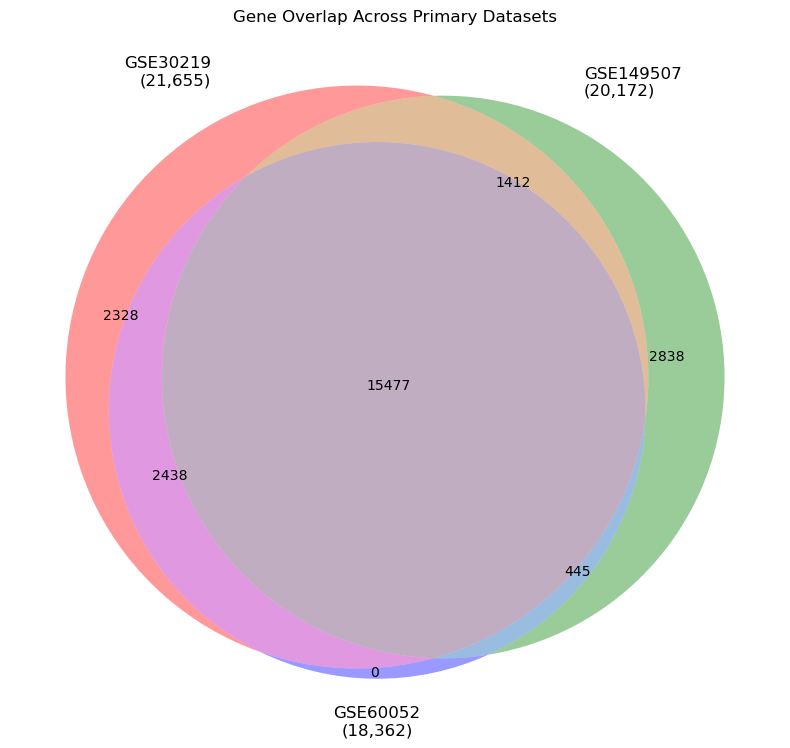

In [9]:
from matplotlib_venn import venn3
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 8))
venn3([genes_30219, genes_149507, genes_60052], 
      set_labels=('GSE30219\n(21,655)', 'GSE149507\n(20,172)', 'GSE60052\n(18,362)'))
plt.title('Gene Overlap Across Primary Datasets')
plt.tight_layout()
plt.savefig('./figures/gene_overlap_venn.png', dpi=150)
plt.show()